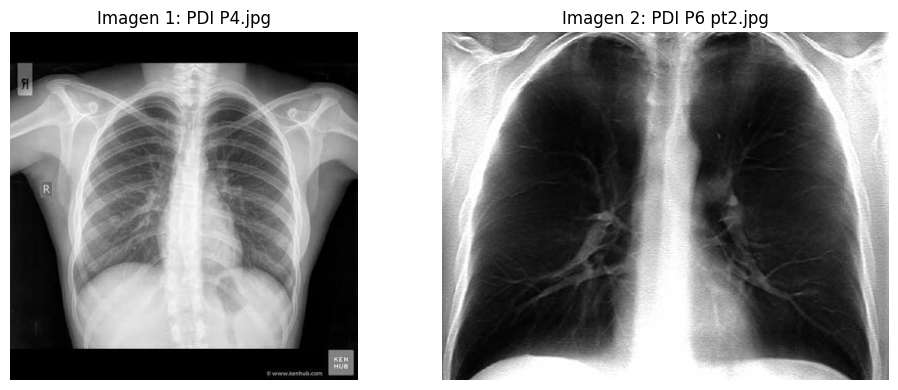

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img1 = cv2.imread("PDI P4.jpg", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("PDI P6 pt2.jpg", cv2.IMREAD_GRAYSCALE)

if img1 is None or img2 is None:
    raise FileNotFoundError("Verifica que 'PDI P4.jpg' y 'PDI P6 pt2.jpg' estén subidas en Colab.")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img1, cmap='gray')
plt.title("Imagen 1: PDI P4.jpg")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img2, cmap='gray')
plt.title("Imagen 2: PDI P6 pt2.jpg")
plt.axis('off')
plt.tight_layout()
plt.show()

**Parte 1** Parte 1.1


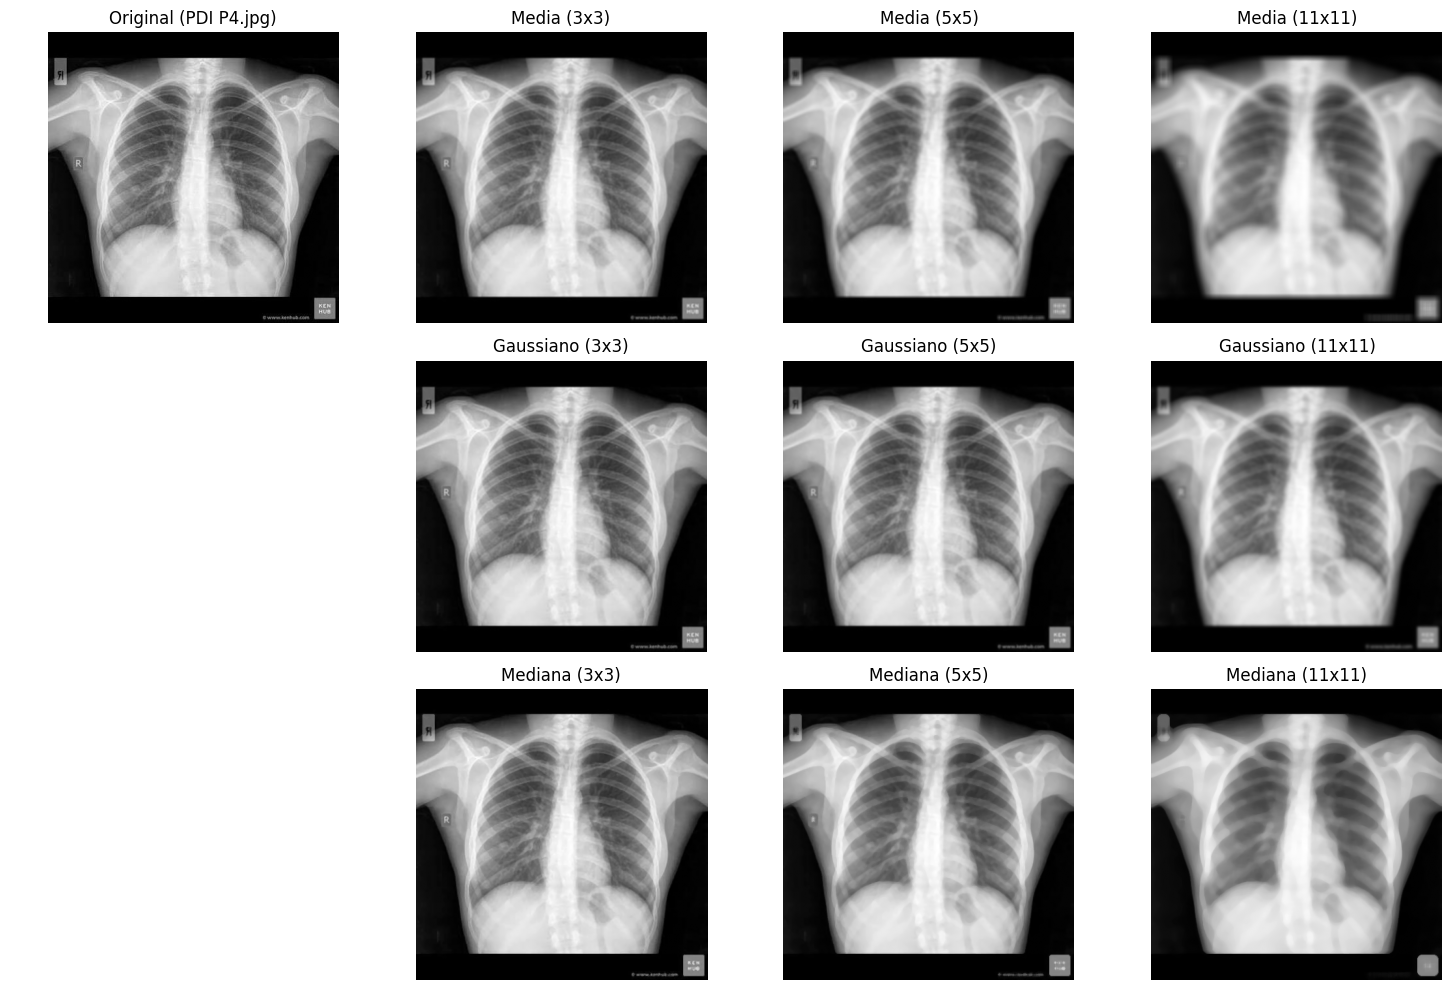

In [2]:
kernels = [3, 5, 11]

plt.figure(figsize=(15, 10))
plt.subplot(3, 4, 1)
plt.imshow(img1, cmap='gray')
plt.title("Original (PDI P4.jpg)")
plt.axis('off')

for idx, k in enumerate(kernels):
    # 1. Filtro de Media
    media = cv2.blur(img1, (k, k))
    plt.subplot(3, 4, idx + 2)
    plt.imshow(media, cmap='gray')
    plt.title(f"Media ({k}x{k})")
    plt.axis('off')

    # 2. Filtro Gaussiano
    gauss = cv2.GaussianBlur(img1, (k, k), 0)
    plt.subplot(3, 4, idx + 6)
    plt.imshow(gauss, cmap='gray')
    plt.title(f"Gaussiano ({k}x{k})")
    plt.axis('off')

    # 3. Filtro de Mediana
    mediana = cv2.medianBlur(img1, k)
    plt.subplot(3, 4, idx + 10)
    plt.imshow(mediana, cmap='gray')
    plt.title(f"Mediana ({k}x{k})")
    plt.axis('off')

plt.subplot(3, 4, 5).axis('off')
plt.subplot(3, 4, 9).axis('off')
plt.tight_layout()
plt.show()

Parte 1.2

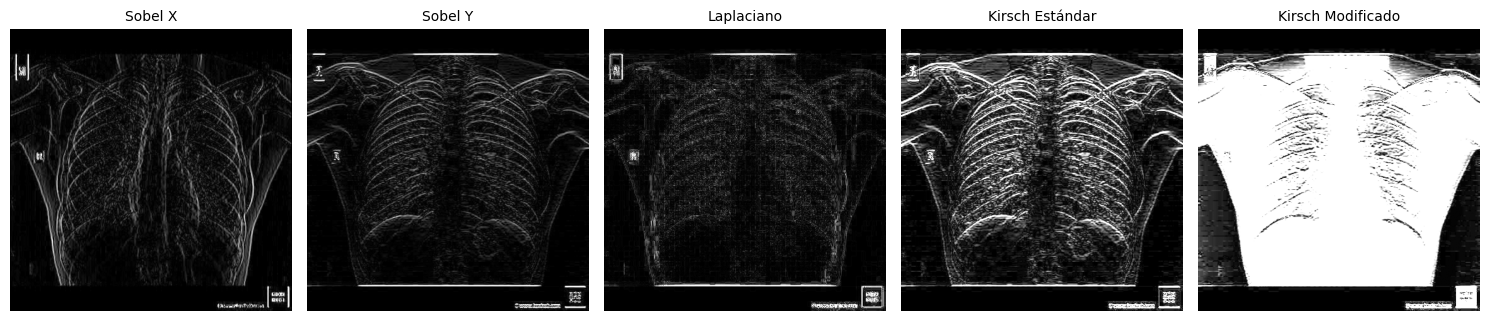

In [3]:
# Sobel en X y Y
sobel_x = cv2.convertScaleAbs(cv2.Sobel(img1, cv2.CV_64F, 1, 0, ksize=3))
sobel_y = cv2.convertScaleAbs(cv2.Sobel(img1, cv2.CV_64F, 0, 1, ksize=3))

# Laplaciano
laplaciano = cv2.convertScaleAbs(cv2.Laplacian(img1, cv2.CV_64F, ksize=3))

# Máscara de Kirsch (Norte) y versión modificada manualmente para mayor énfasis
kirsch_norte = np.array([
    [ 5,  5,  5],
    [-3,  0, -3],
    [-3, -3, -3]
], dtype=np.float32)

kirsch_modificado = np.array([
    [ 8,  8,  8],
    [-4,  0, -4],
    [-4, -4, -4]
], dtype=np.float32)

res_kirsch = cv2.convertScaleAbs(cv2.filter2D(img1, cv2.CV_64F, kirsch_norte))
res_kirsch_mod = cv2.convertScaleAbs(cv2.filter2D(img1, cv2.CV_64F, kirsch_modificado))

plt.figure(figsize=(15, 4))
titulos_bordes = ["Sobel X", "Sobel Y", "Laplaciano", "Kirsch Estándar", "Kirsch Modificado"]
imgs_bordes = [sobel_x, sobel_y, laplaciano, res_kirsch, res_kirsch_mod]

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(imgs_bordes[i], cmap='gray')
    plt.title(titulos_bordes[i], fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

Parte 1.3

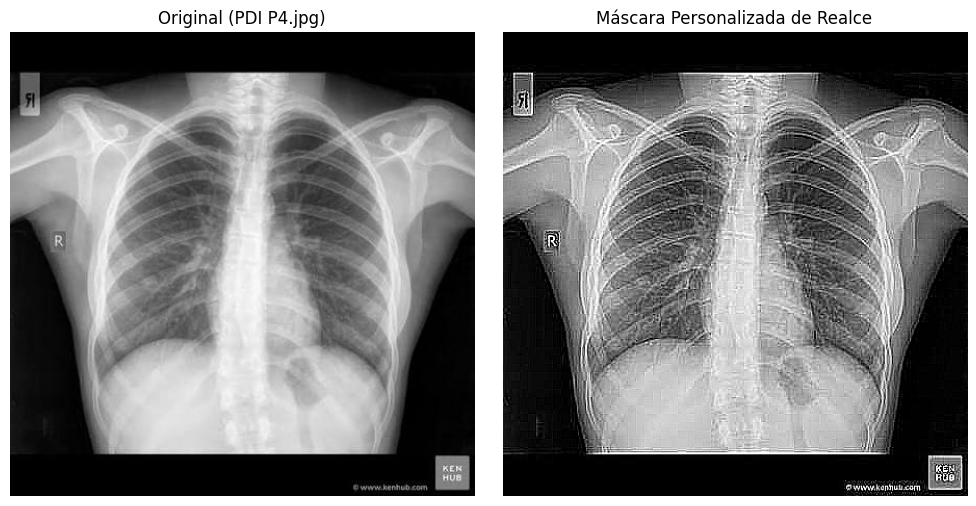

In [4]:
mascara_personalizada = np.array([
    [-1, -1, -1],
    [-1,  9, -1],
    [-1, -1, -1]
], dtype=np.float32)

img_realzada = cv2.filter2D(img1, -1, mascara_personalizada)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img1, cmap='gray')
plt.title("Original (PDI P4.jpg)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_realzada, cmap='gray')
plt.title("Máscara Personalizada de Realce")
plt.axis('off')
plt.tight_layout()
plt.show()

**Parte 2**


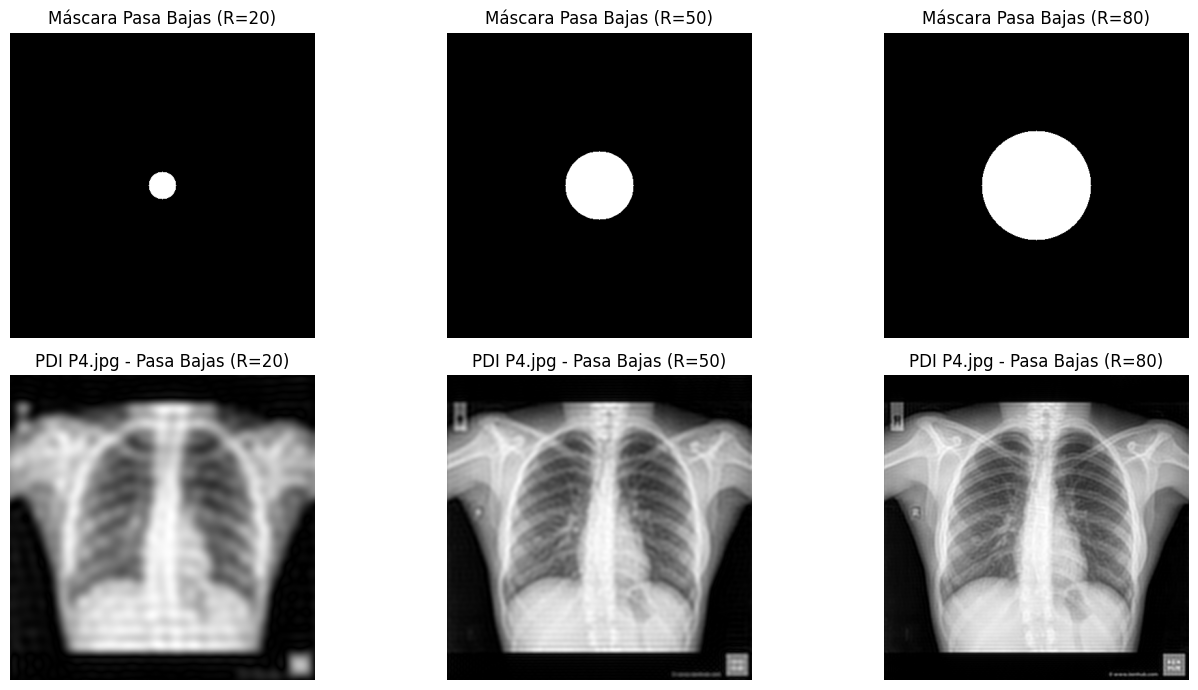

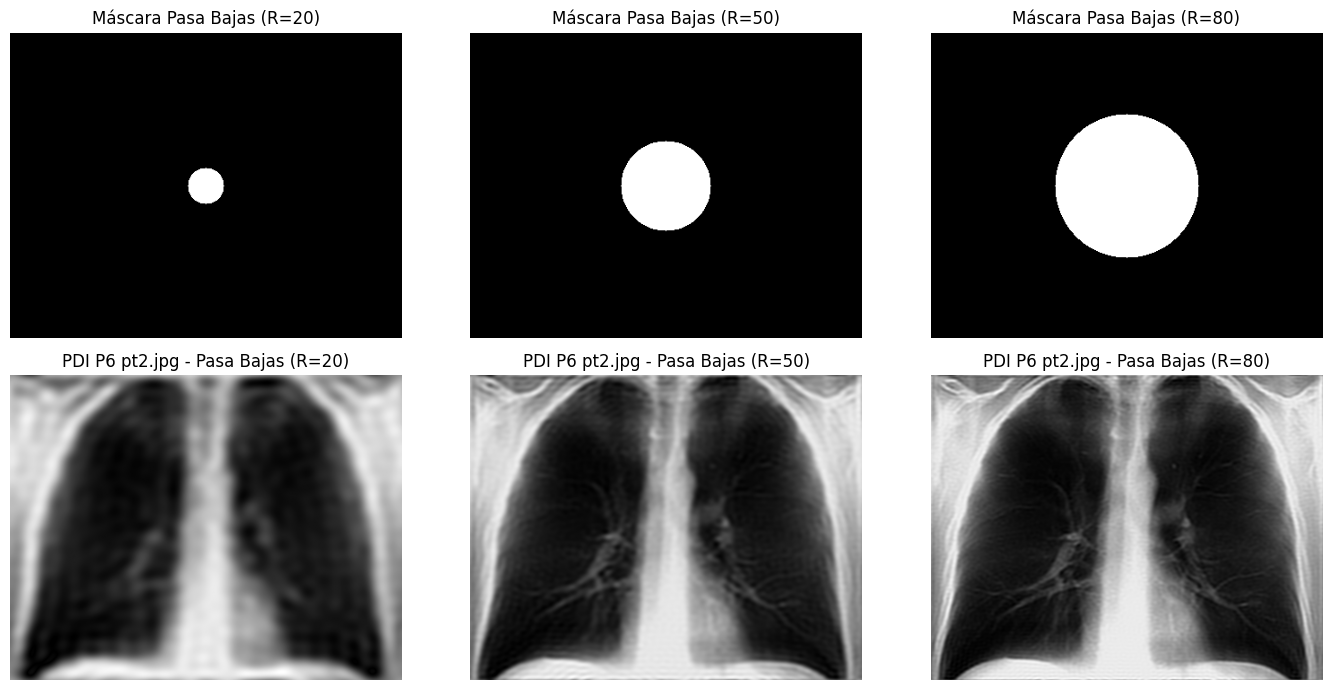

In [5]:
def aplicar_pasa_bajas(imagen, nombre_img, radios=[20, 50, 80]):
    f = np.fft.fft2(imagen)
    fshift = np.fft.fftshift(f)
    alto, ancho = imagen.shape
    cy, cx = alto // 2, ancho // 2
    y, x = np.ogrid[-cy:alto - cy, -cx:ancho - cx]

    plt.figure(figsize=(14, 7))
    for idx, r in enumerate(radios):
        mascara = np.zeros((alto, ancho), dtype=np.float32)
        mascara[x*x + y*y <= r*r] = 1.0

        f_filtrada = fshift * mascara
        img_inv = np.abs(np.fft.ifft2(np.fft.ifftshift(f_filtrada)))

        plt.subplot(2, 3, idx + 1)
        plt.imshow(mascara, cmap='gray')
        plt.title(f"Máscara Pasa Bajas (R={r})")
        plt.axis('off')

        plt.subplot(2, 3, idx + 4)
        plt.imshow(img_inv, cmap='gray')
        plt.title(f"{nombre_img} - Pasa Bajas (R={r})")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Aplicar a las dos imágenes médicas
aplicar_pasa_bajas(img1, "PDI P4.jpg")
aplicar_pasa_bajas(img2, "PDI P6 pt2.jpg")

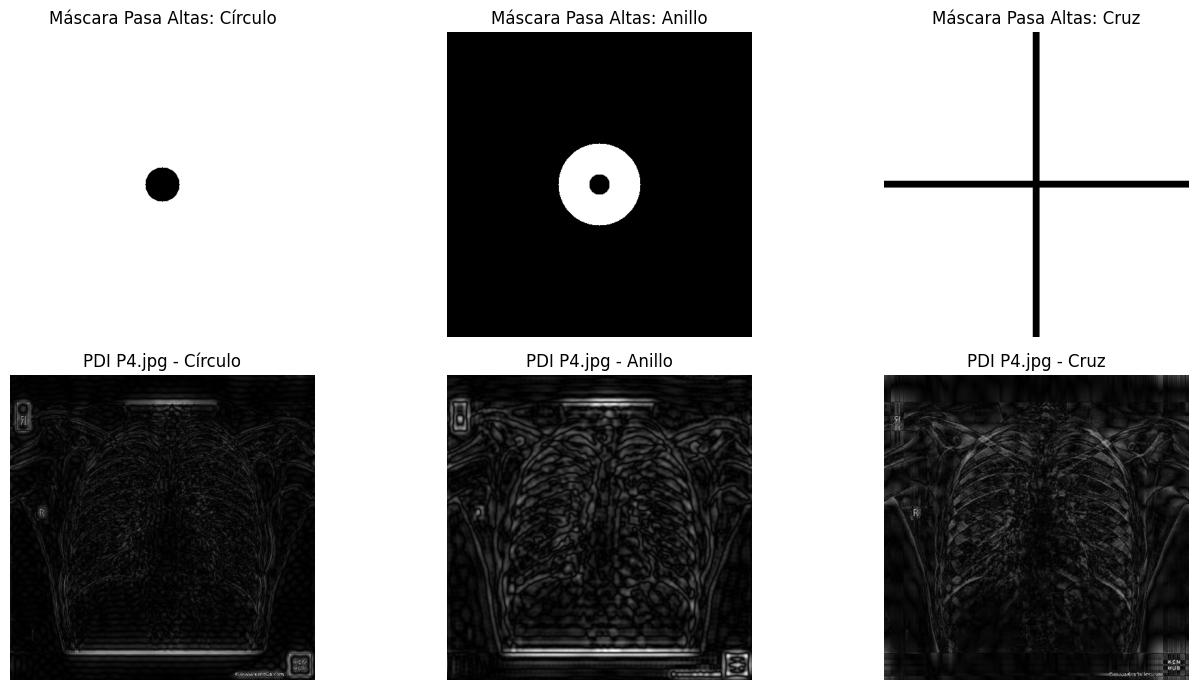

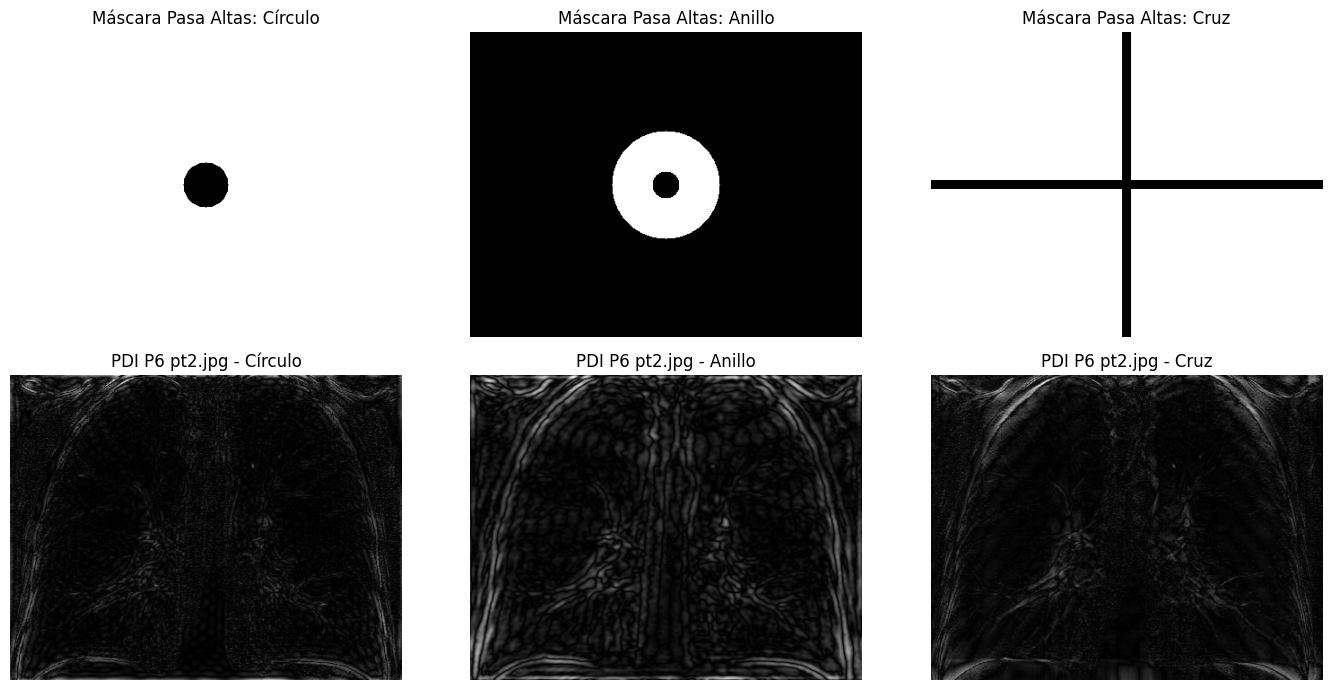

In [6]:
def aplicar_pasa_altas(imagen, nombre_img):
    f = np.fft.fft2(imagen)
    fshift = np.fft.fftshift(f)
    alto, ancho = imagen.shape
    cy, cx = alto // 2, ancho // 2
    y, x = np.ogrid[-cy:alto - cy, -cx:ancho - cx]
    dist2 = x*x + y*y

    # 1. Pasa altas circular (bloquea bajas frecuencias centrales R <= 25)
    m_circulo = np.ones((alto, ancho), dtype=np.float32)
    m_circulo[dist2 <= 25**2] = 0.0

    # 2. Pasa altas tipo anillo (banda de paso entre R=15 y R=60)
    m_anillo = np.zeros((alto, ancho), dtype=np.float32)
    m_anillo[(dist2 >= 15**2) & (dist2 <= 60**2)] = 1.0

    # 3. Pasa altas en cruz (atenúa ejes centrales vertical y horizontal)
    m_cruz = np.ones((alto, ancho), dtype=np.float32)
    m_cruz[:, cx - 5 : cx + 5] = 0.0
    m_cruz[cy - 5 : cy + 5, :] = 0.0

    mascaras = [m_circulo, m_anillo, m_cruz]
    nombres_m = ["Círculo", "Anillo", "Cruz"]

    plt.figure(figsize=(14, 7))
    for idx in range(3):
        f_filtrada = fshift * mascaras[idx]
        img_inv = np.abs(np.fft.ifft2(np.fft.ifftshift(f_filtrada)))

        plt.subplot(2, 3, idx + 1)
        plt.imshow(mascaras[idx], cmap='gray')
        plt.title(f"Máscara Pasa Altas: {nombres_m[idx]}")
        plt.axis('off')

        plt.subplot(2, 3, idx + 4)
        plt.imshow(img_inv, cmap='gray')
        plt.title(f"{nombre_img} - {nombres_m[idx]}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Aplicar a las dos imágenes médicas
aplicar_pasa_altas(img1, "PDI P4.jpg")
aplicar_pasa_altas(img2, "PDI P6 pt2.jpg")